# Oracle Construction — Arithmetic Oracle — CUDA-Q Notebook

**Primitive:** Arithmetic (modular-condition) phase oracle marking every basis state `x`
with `x mod MODULUS == REMAINDER`, built as a union of single-target phase-flip sub-oracles.

This notebook is the CUDA-Q counterpart to `arith_oracle_qiskit.ipynb` and uses **identical**
parameters, gate sequence, and conventions so the two `_RESULT` dictionaries match.

## SETUP (identical to the Qiskit notebook)
| Parameter | Value |
|---|---|
| N_QUBITS | 3 |
| MODULUS | 3 |
| REMAINDER | 0 |
| MARKED_SET | `{0, 3, 6}` |
| SHOTS | 10000 |
| SEED | 42 |
| QUBIT ORDERING CONTRACT | qubit 0 = **rightmost** bit in every printed bitstring (this notebook explicitly reverses CUDA-Q's native output to match) |
| GLOBAL PHASE CONVENTION | normalize so the first amplitude with `abs(amp) > 1e-9`, taken in ascending bitstring order, is rotated to be real and positive |
| Basis ordering for matrices | `{|000>, |001>, ..., |111>}` ascending binary order |

## Theory recap

Same as the Qiskit notebook: for each `m` in `{0, 3, 6}`, apply the standard `X`-sandwich
`H`-`MCX`-`H` `X`-undo single-target phase flip. Probabilities stay uniform `1/8` (diagonal
`±1` operator) -- the arithmetic predicate is visible only in the statevector sign pattern.

## ⚠️ Ordering-convention warning

CUDA-Q's `cudaq.get_state()` and `cudaq.sample()` index **qubit 0 as the most-significant
(leftmost) bit** -- the opposite of Qiskit. Every raw CUDA-Q bitstring/index in this notebook
is explicitly reversed in its own dedicated cell before comparison to the Qiskit notebook.

## Environment note

CUDA-Q's Python wheel (`cudaq`) ships for **Linux (x86_64 / aarch64)**, Python 3.10-3.12,
CPU simulator by default (`cudaq.set_target("qpp-cpu")`) -- no GPU required. On
Windows/macOS use the official `nvcr.io/nvidia/cuda-quantum` Docker image.

**Run all cells top to bottom.**


In [1]:
# Install cell
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 77.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 81.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 8.0 MB/s eta 0:00

In [2]:
# Imports + constants (identical values to the Qiskit notebook)
import numpy as np
from math import pi
import cudaq
import matplotlib.pyplot as plt

N_QUBITS = 3
MODULUS = 3
REMAINDER = 0
MARKED_SET = [x for x in range(2**N_QUBITS) if x % MODULUS == REMAINDER]
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "arith_oracle"

cudaq.set_target("qpp-cpu")
cudaq.set_random_seed(SEED)

print("N_QUBITS   =", N_QUBITS)
print("MARKED_SET =", MARKED_SET, [format(m, f'0{N_QUBITS}b') for m in MARKED_SET])
print("SHOTS      =", SHOTS)
print("SEED       =", SEED)
print("Target     =", cudaq.get_target().name)


N_QUBITS   = 3
MARKED_SET = [0, 3, 6] ['000', '011', '110']
SHOTS      = 10000
SEED       = 42
Target     = qpp-cpu


In [3]:
# Build the kernel gate-by-gate
# MARKED_SET = {0, 3, 6} is hardcoded below as explicit gate calls per marked value
# (rather than a runtime conditional) for maximum kernel-compiler compatibility.
# m=0 (000): zero-bit qubits = [0,1,2] -> X on all three before/after the MCZ sandwich
# m=3 (011): zero-bit qubits = [2]     -> X on q2 before/after
# m=6 (110): zero-bit qubits = [0]     -> X on q0 before/after

@cudaq.kernel
def arith_oracle_kernel():
    qubits = cudaq.qvector(3)  # N_QUBITS hardcoded to 3 inside the kernel (must be a literal)

    h(qubits[0]); h(qubits[1]); h(qubits[2])   # test harness: uniform superposition

    # --- sub-oracle for m=0 (binary 000) ---
    x(qubits[0]); x(qubits[1]); x(qubits[2])
    h(qubits[2]); x.ctrl(qubits[0], qubits[1], qubits[2]); h(qubits[2])
    x(qubits[0]); x(qubits[1]); x(qubits[2])

    # --- sub-oracle for m=3 (binary 011) ---
    x(qubits[2])
    h(qubits[2]); x.ctrl(qubits[0], qubits[1], qubits[2]); h(qubits[2])
    x(qubits[2])

    # --- sub-oracle for m=6 (binary 110) ---
    x(qubits[0])
    h(qubits[2]); x.ctrl(qubits[0], qubits[1], qubits[2]); h(qubits[2])
    x(qubits[0])

# Mirror the same gate list in plain Python (used for resource counts, the matplotlib
# circuit diagram, and the hand-built matrix cross-check below) so it stays in lockstep
# with the kernel body above by construction.
gatelist = [('H', q) for q in range(N_QUBITS)]
for m in MARKED_SET:
    zero_bit_qubits = [q for q in range(N_QUBITS) if not ((m >> q) & 1)]
    gatelist += [('X', q) for q in zero_bit_qubits]
    gatelist.append(('H', N_QUBITS - 1))
    gatelist.append(('MCX', list(range(N_QUBITS - 1)), N_QUBITS - 1))
    gatelist.append(('H', N_QUBITS - 1))
    gatelist += [('X', q) for q in zero_bit_qubits]

print("Gate list (", len(gatelist), "gates ) matches the kernel body above.")


Gate list ( 22 gates ) matches the kernel body above.


     ╭───╮╭───╮          ╭───╮                    ╭───╮               ╭───╮
q0 : ┤ h ├┤ x ├───────●──┤ x ├─────────────────●──┤ x ├────────────●──┤ x ├
     ├───┤├───┤       │  ├───┤                 │  ╰───╯            │  ╰───╯
q1 : ┤ h ├┤ x ├───────●──┤ x ├─────────────────●───────────────────●───────
     ├───┤├───┤╭───╮╭─┴─╮├───┤╭───╮╭───╮╭───╮╭─┴─╮╭───╮╭───╮╭───╮╭─┴─╮╭───╮
q2 : ┤ h ├┤ x ├┤ h ├┤ x ├┤ h ├┤ x ├┤ x ├┤ h ├┤ x ├┤ h ├┤ x ├┤ h ├┤ x ├┤ h ├
     ╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯



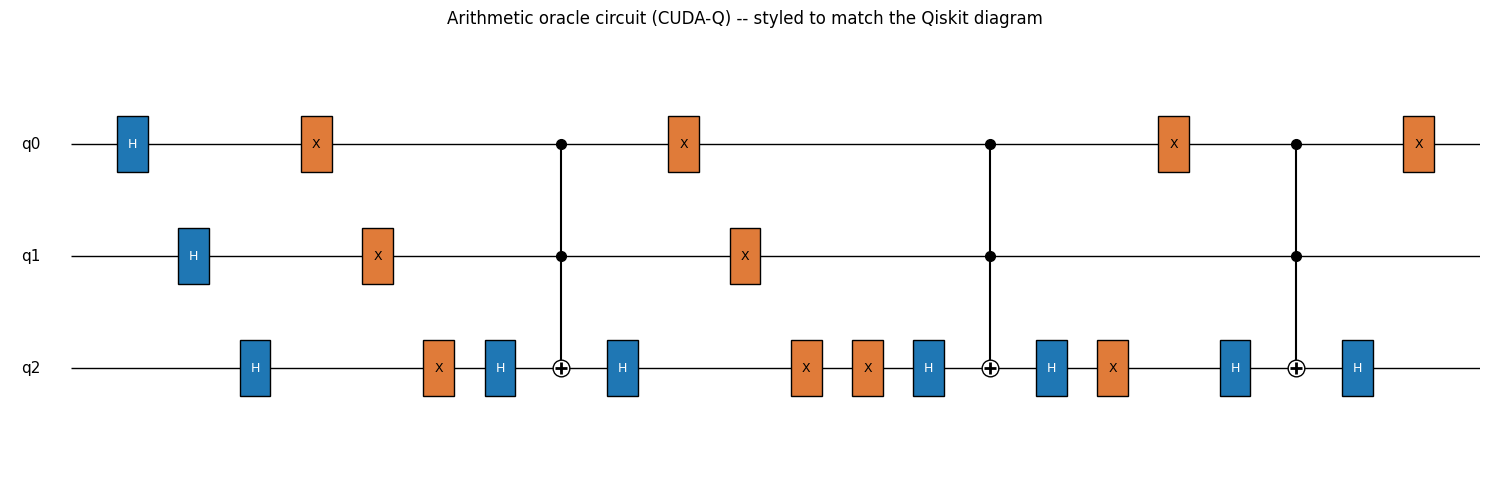

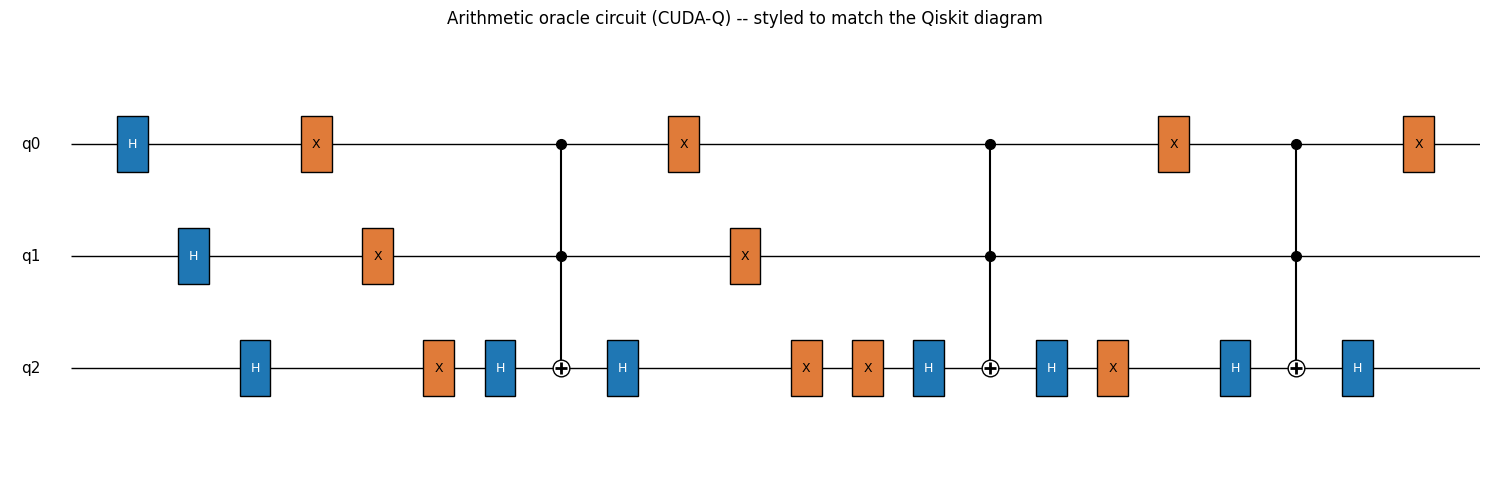

In [4]:
# Draw the circuit: cudaq's own text diagram, then a matplotlib figure styled like Qiskit's
print(cudaq.draw(arith_oracle_kernel))

fig, ax = plt.subplots(figsize=(15, 5))
n_wires = N_QUBITS
wire_y = {q: n_wires - 1 - q for q in range(n_wires)}

col = 0
col_positions = {}
for gate in gatelist:
    col += 1
    col_positions[id(gate)] = col
n_cols = col + 1

for q in range(n_wires):
    ax.hlines(wire_y[q], 0, n_cols, color="black", linewidth=1, zorder=1)
    ax.text(-0.5, wire_y[q], f"q{q}", va="center", ha="right", fontsize=11)

for gate in gatelist:
    x_pos = col_positions[id(gate)]
    if gate[0] == 'X':
        _, q = gate
        ax.add_patch(plt.Rectangle((x_pos - 0.25, wire_y[q] - 0.25), 0.5, 0.5, facecolor="#e07b39", edgecolor="black", zorder=2))
        ax.text(x_pos, wire_y[q], "X", ha="center", va="center", fontsize=9, zorder=3)
    elif gate[0] == 'H':
        _, q = gate
        ax.add_patch(plt.Rectangle((x_pos - 0.25, wire_y[q] - 0.25), 0.5, 0.5, facecolor="#1f77b4", edgecolor="black", zorder=2))
        ax.text(x_pos, wire_y[q], "H", ha="center", va="center", fontsize=9, color="white", zorder=3)
    elif gate[0] == 'MCX':
        _, controls, target = gate
        all_q = controls + [target]
        ax.vlines(x_pos, wire_y[min(all_q)], wire_y[max(all_q)], color="black", zorder=2)
        for c in controls:
            ax.plot(x_pos, wire_y[c], marker="o", color="black", markersize=7, zorder=3)
        ax.plot(x_pos, wire_y[target], marker="o", color="white", markeredgecolor="black", markersize=12, zorder=3)
        ax.plot(x_pos, wire_y[target], marker="+", color="black", markersize=8, mew=2, zorder=4)

ax.set_xlim(-1, n_cols)
ax.set_ylim(-1, n_wires)
ax.axis("off")
ax.set_title("Arithmetic oracle circuit (CUDA-Q) -- styled to match the Qiskit diagram")
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_cudaq_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation, built two independent ways, cross-checked
# CUDA-Q has no dense-operator-extraction API, so the cross-check here is against
# CUDA-Q's own statevector simulation (cudaq.get_state), applied to |000>.

def h_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        bit = (idx >> q) & 1
        idx0 = idx & ~(1 << q); idx1 = idx | (1 << q)
        if bit == 0:
            M[idx0, idx] += 1/np.sqrt(2); M[idx1, idx] += 1/np.sqrt(2)
        else:
            M[idx1, idx] += -1/np.sqrt(2); M[idx0, idx] += 1/np.sqrt(2)
    return M

def x_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        M[idx ^ (1 << q), idx] = 1
    return M

def mcx_matrix_full(n, controls, target):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        if all((idx >> c) & 1 for c in controls):
            M[idx ^ (1 << target), idx] = 1
        else:
            M[idx, idx] = 1
    return M

ideal_diag = np.array([-1.0 if x in MARKED_SET else 1.0 for x in range(2**N_QUBITS)], dtype=complex)
print("Ideal arithmetic-oracle matrix: diagonal, -1 at each marked index, +1 elsewhere:")
print(np.round(np.diag(ideal_diag), 4))

# (a) Hand-built full unitary in QISKIT-CONVENTION indexing
U_hand = np.eye(2**N_QUBITS, dtype=complex)
for q in range(N_QUBITS):
    U_hand = h_matrix_full(N_QUBITS, q) @ U_hand
for m in MARKED_SET:
    zero_bit_qubits = [q for q in range(N_QUBITS) if not ((m >> q) & 1)]
    for q in zero_bit_qubits:
        U_hand = x_matrix_full(N_QUBITS, q) @ U_hand
    U_hand = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_hand
    U_hand = mcx_matrix_full(N_QUBITS, list(range(N_QUBITS - 1)), N_QUBITS - 1) @ U_hand
    U_hand = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_hand
    for q in zero_bit_qubits:
        U_hand = x_matrix_full(N_QUBITS, q) @ U_hand

state_hand = U_hand[:, 0]

# (b) CUDA-Q's own statevector simulation, then reversed into qiskit-convention indexing
sv_raw = np.array(cudaq.get_state(arith_oracle_kernel))
state_cudaq_qiskit_conv = np.zeros(2**N_QUBITS, dtype=complex)
for k in range(2**N_QUBITS):
    raw_bits = format(k, f'0{N_QUBITS}b')
    qiskit_bits = raw_bits[::-1]
    state_cudaq_qiskit_conv[int(qiskit_bits, 2)] = sv_raw[k]

def normalize_phase(vec):
    vec = vec.copy()
    for idx in range(len(vec)):
        if abs(vec[idx]) > 1e-9:
            vec = vec * np.exp(-1j*np.angle(vec[idx]))
            break
    return vec

max_state_diff = np.max(np.abs(normalize_phase(state_hand) - normalize_phase(state_cudaq_qiskit_conv)))
print(f"\nMax |difference| between hand-built matrix applied to |0> and cudaq.get_state() (both reordered, phase-normalized): {max_state_diff:.3e}")
assert max_state_diff < 1e-6
print("Hand-built statevector and CUDA-Q's own simulation MATCH.")

# isolate oracle-only sub-circuit and check against ideal diagonal
U_oracle_only = np.eye(2**N_QUBITS, dtype=complex)
for m in MARKED_SET:
    zero_bit_qubits = [q for q in range(N_QUBITS) if not ((m >> q) & 1)]
    for q in zero_bit_qubits:
        U_oracle_only = x_matrix_full(N_QUBITS, q) @ U_oracle_only
    U_oracle_only = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_oracle_only
    U_oracle_only = mcx_matrix_full(N_QUBITS, list(range(N_QUBITS - 1)), N_QUBITS - 1) @ U_oracle_only
    U_oracle_only = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_oracle_only
    for q in zero_bit_qubits:
        U_oracle_only = x_matrix_full(N_QUBITS, q) @ U_oracle_only

max_oracle_diff = np.max(np.abs(U_oracle_only - np.diag(ideal_diag)))
print(f"Max |difference| between oracle-only matrix and ideal diagonal: {max_oracle_diff:.3e}")
assert max_oracle_diff < 1e-8
print("Oracle-only matrix MATCHES the ideal arithmetic-predicate diagonal.")


Ideal arithmetic-oracle matrix: diagonal, -1 at each marked index, +1 elsewhere:
[[-1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j -1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j -1.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  1.+0.j]]

Max |difference| between hand-built matrix applied to |0> and cudaq.get_state() (both reordered, phase-normalized): 0.000e+00
Hand-built statevector and CUDA-Q's own simulation MATCH.
Max |difference| between oracle-only matrix and ideal diagonal: 6.661e-16
Oracle-only matrix MATCHES the ideal arithmetic-predicate diagonal.


In [6]:
# Bit-order reversal cell: raw CUDA-Q statevector -> qiskit-convention amplitudes
sv_raw = np.array(cudaq.get_state(arith_oracle_kernel))

amps = np.zeros(2**N_QUBITS, dtype=complex)
for k in range(2**N_QUBITS):
    raw_bits = format(k, f'0{N_QUBITS}b')
    qiskit_bits = raw_bits[::-1]
    amps[int(qiskit_bits, 2)] = sv_raw[k]

print("Reversal applied: for each raw cudaq index, its bitstring was reversed and re-parsed as an")
print("integer index so that qubit 0 becomes the rightmost character, matching the Qiskit notebook.")


Reversal applied: for each raw cudaq index, its bitstring was reversed and re-parsed as an
integer index so that qubit 0 becomes the rightmost character, matching the Qiskit notebook.


In [7]:
# Exact statevector: apply global-phase normalization, print
for idx in range(len(amps)):
    if abs(amps[idx]) > 1e-9:
        phase = np.angle(amps[idx])
        amps = amps * np.exp(-1j*phase)
        break

print(f"{'bitstring':10s} {'amplitude':22s} {'probability':12s}")
CUDAQ_PROBS_EXACT = {}
for idx in range(2**N_QUBITS):
    bitstring = format(idx, f'0{N_QUBITS}b')
    amp = amps[idx]
    prob = abs(amp)**2
    CUDAQ_PROBS_EXACT[bitstring] = prob
    marker = "  <-- x mod 3 == 0 (marked)" if idx in MARKED_SET else ""
    print(f"|{bitstring}>   {amp.real:+.6f}{amp.imag:+.6f}j    {prob:.6f}{marker}")

print("\nProbabilities sum to:", sum(CUDAQ_PROBS_EXACT.values()))


bitstring  amplitude              probability 
|000>   +0.353553+0.000000j    0.125000  <-- x mod 3 == 0 (marked)
|001>   -0.353553-0.000000j    0.125000
|010>   -0.353553-0.000000j    0.125000
|011>   +0.353553+0.000000j    0.125000  <-- x mod 3 == 0 (marked)
|100>   -0.353553-0.000000j    0.125000
|101>   -0.353553-0.000000j    0.125000
|110>   +0.353553+0.000000j    0.125000  <-- x mod 3 == 0 (marked)
|111>   -0.353553-0.000000j    0.125000

Probabilities sum to: 0.9999999999999984


### Ordering-fix note (CUDA-Q)

**A bit reversal WAS applied.** `cudaq.get_state()` indexes qubit 0 as the leftmost
character; each raw index was reformatted as an `N_QUBITS`-bit binary string, reversed, and
re-parsed as the new index, so qubit 0 becomes the rightmost character -- matching Qiskit.
This is a pure relabeling and does not change any amplitude's value.


In [8]:
# Measurement: sample with the shared SEED/SHOTS, get counts -> probabilities, reorder bitstrings
cudaq.set_random_seed(SEED)
result = cudaq.sample(arith_oracle_kernel, shots_count=SHOTS)

CUDAQ_PROBS_SAMPLED = {format(idx, f'0{N_QUBITS}b'): 0.0 for idx in range(2**N_QUBITS)}
for raw_bitstring, count in result.items():
    qiskit_bitstring = raw_bitstring[::-1]
    CUDAQ_PROBS_SAMPLED[qiskit_bitstring] = count / SHOTS

print("Sampled probabilities (from", SHOTS, "shots, seed =", SEED, "), reordered to qiskit convention:")
for bitstring in sorted(CUDAQ_PROBS_SAMPLED):
    print(f"|{bitstring}>   {CUDAQ_PROBS_SAMPLED[bitstring]:.4f}")


Sampled probabilities (from 10000 shots, seed = 42 ), reordered to qiskit convention:
|000>   0.1284
|001>   0.1166
|010>   0.1232
|011>   0.1265
|100>   0.1283
|101>   0.1297
|110>   0.1291
|111>   0.1182


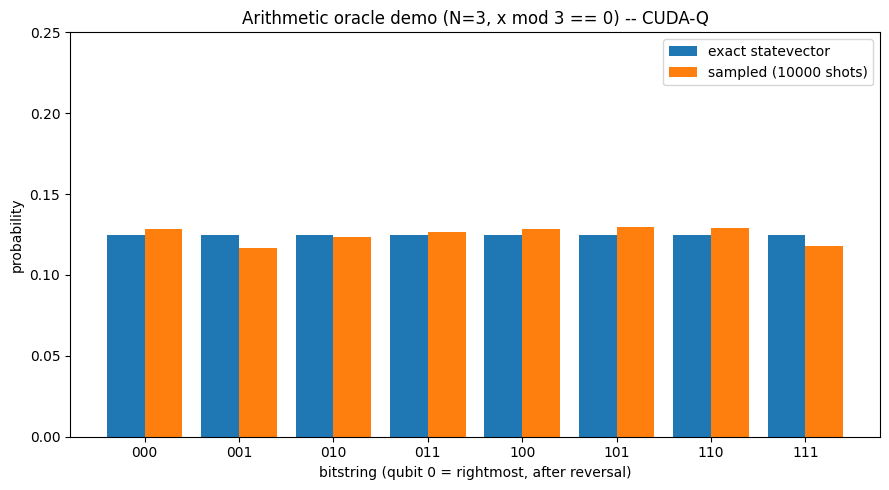

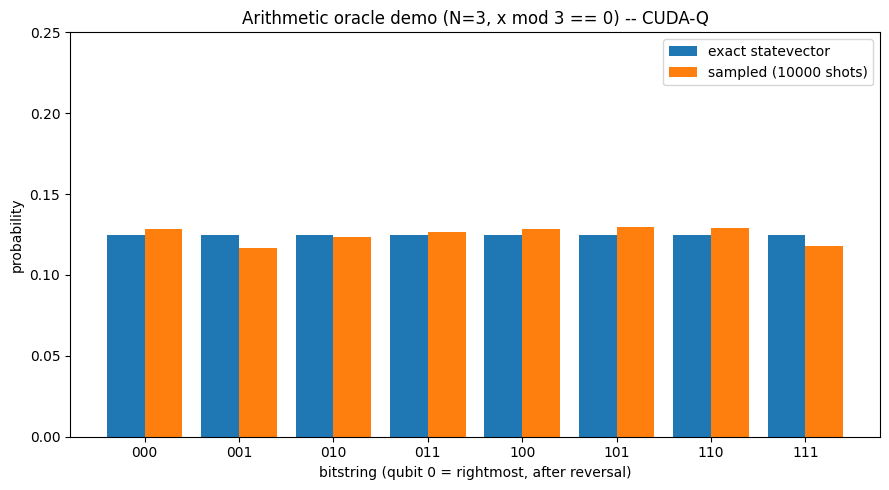

In [9]:
# Histogram: matplotlib bar chart, same style/axis ranges as the Qiskit notebook, saved to file
bitstrings_sorted = sorted(CUDAQ_PROBS_EXACT.keys())
exact_vals = [CUDAQ_PROBS_EXACT[b] for b in bitstrings_sorted]
sampled_vals = [CUDAQ_PROBS_SAMPLED[b] for b in bitstrings_sorted]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(bitstrings_sorted))
width = 0.4
ax.bar(x - width/2, exact_vals, width, label="exact statevector", color="#1f77b4")
ax.bar(x + width/2, sampled_vals, width, label=f"sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(bitstrings_sorted, rotation=0)
ax.set_xlabel("bitstring (qubit 0 = rightmost, after reversal)")
ax.set_ylabel("probability")
ax.set_title(f"Arithmetic oracle demo (N={N_QUBITS}, x mod {MODULUS} == {REMAINDER}) -- CUDA-Q")
ax.set_ylim(0, 0.25)
ax.legend()
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig


In [10]:
# Resource counts
from collections import Counter
gate_type_counts = Counter(g[0] for g in gatelist)
print("Gate counts:", dict(gate_type_counts))
print("Total gate count:", len(gatelist))
print("Sub-oracles applied:", len(MARKED_SET))


Gate counts: {'H': 9, 'X': 10, 'MCX': 3}
Total gate count: 22
Sub-oracles applied: 3


### Convention notes (plain text summary)

- **Bit-order convention:** qubit 0 = rightmost character; CUDA-Q's raw output is the
  opposite, **reversal applied** to both the statevector and sampled counts.
- **Global phase convention:** identical rule to the Qiskit notebook.
- **Basis ordering:** ascending binary order `|000> ... |111>`.
- **Why the histogram is flat:** diagonal `±1` matrix, same reasoning as the Qiskit
  notebook -- probabilities are unaffected, only the sign pattern changes.


In [11]:
# Final result
CUDAQ_RESULT = {b: CUDAQ_PROBS_EXACT[b] for b in sorted(CUDAQ_PROBS_EXACT)}
print("CUDAQ_RESULT =")
for b, p in CUDAQ_RESULT.items():
    print(f"  '{b}': {p:.6f}")


CUDAQ_RESULT =
  '000': 0.125000
  '001': 0.125000
  '010': 0.125000
  '011': 0.125000
  '100': 0.125000
  '101': 0.125000
  '110': 0.125000
  '111': 0.125000


In [12]:
# Diff-check block (run AFTER also running the Qiskit notebook and pasting its QISKIT_RESULT below)
HAND_COMPUTED_EXPECTED = {format(i, f'0{N_QUBITS}b'): 1/(2**N_QUBITS) for i in range(2**N_QUBITS)}
max_delta_vs_hand = max(abs(CUDAQ_RESULT[b] - HAND_COMPUTED_EXPECTED[b]) for b in CUDAQ_RESULT)
print("Max delta between CUDAQ_RESULT and hand-computed expected (uniform 1/8):", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-3

# QISKIT_RESULT = { ... }  # <- paste the dict printed at the end of the Qiskit notebook here
# max_delta = max(abs(CUDAQ_RESULT[b] - QISKIT_RESULT[b]) for b in CUDAQ_RESULT)
# print("Max probability delta between QISKIT_RESULT and CUDAQ_RESULT:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q arithmetic-oracle results disagree beyond tolerance!"


Max delta between CUDAQ_RESULT and hand-computed expected (uniform 1/8): 1.8041124150158794e-16
